# COMP9417 Project: starter notebook

This notebook loads the dataset, shows how day D and day D+1 are defined, builds a day-ahead
table for both targets, and computes the two required baselines by year. It ends with a very
simple model trained on 2010-2013 so you can see the evaluation protocol in action.

Run it from the kit's root folder, with the libraries in `requirements.txt` installed.

In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "harness")
import dayahead as da          # the same helpers the marking runner uses

df = da.load_dataset("data/nem_weather_halfhourly_2010_2026.csv")
print(df.shape, df.index.min(), "to", df.index.max())
df.head()

## Timestamps and days

Each timestamp marks the **end** of a half-hour interval, in market time (AEST, UTC+10, no
daylight saving). Day D is made of the 48 intervals stamped D 00:30, D 01:00, ..., D 23:30 and
D+1 00:00. `da.market_day` maps each timestamp to its day.

In [ ]:
df["day"] = da.market_day(df.index)
df["period"] = ((df.index - pd.Timedelta("30min")).hour * 2
                + (df.index - pd.Timedelta("30min")).minute // 30)   # 0..47
df[["day", "period", "nsw_demand", "nsw_price"]].iloc[44:52]

## A first look at drift

Midday demand has fallen as rooftop solar has grown, while the evening peak has not.
Negative prices were almost unknown before 2020.

In [ ]:
year = df.index.year
noon = df["period"].isin([23, 24, 25, 26])      # 11:30-13:30
evening = df["period"].isin([37, 38, 39])       # 18:30-20:00
summary = pd.DataFrame({
    "midday demand (MW)": df.loc[noon, "nsw_demand"].groupby(year[noon]).mean(),
    "evening demand (MW)": df.loc[evening, "nsw_demand"].groupby(year[evening]).mean(),
    "negative-price share (%)": (df["nsw_price"] < 0).groupby(year).mean() * 100,
}).round(1)
ax = summary[["midday demand (MW)", "evening demand (MW)"]].plot(marker="o", figsize=(9, 4))
ax.set_ylabel("NSW demand (MW)"); ax.set_title("Average NSW demand by year")
plt.show()
summary

## The day-ahead table

One row per half-hour of day D+1. Targets: demand (MW), and whether the price is above
the mean price of day D. Inputs here are only examples: values from day D and day D-6
(same half-hour yesterday and last week) and the weather for D+1. Designing better inputs is
part of your work. Everything is shifted by whole days, so no information from D+1's market
values leaks into the inputs.

In [ ]:
daily_price_mean = df.groupby("day")["nsw_price"].transform("mean")
t = pd.DataFrame(index=df.index)
t["day"], t["period"] = df["day"], df["period"]
t["y_demand"] = df["nsw_demand"]
t["y_up"] = (df["nsw_price"] > daily_price_mean.shift(48)).astype(int)
t["demand_lag1"] = df["nsw_demand"].shift(48)         # same half-hour yesterday
t["demand_lag7"] = df["nsw_demand"].shift(48 * 7)     # same half-hour last week
t["up_lag1"] = (df["nsw_price"].shift(48) > daily_price_mean.shift(48)).astype(int)
t["up_lag7"] = (df["nsw_price"].shift(48 * 7) > daily_price_mean.shift(48)).astype(int)  # vs day D mean
for c in da.WEATHER_COLS:
    t[c] = df[c]                                      # weather of D+1 itself (allowed)
t = t.iloc[48 * 7:].dropna()
t["year"] = t["day"].dt.year
t.head()

## Baselines by year

Both baselines must be reported in your project. They are hard to beat.

In [ ]:
def yearly(t, pred_demand, pred_up):
    g = t.assign(pd_=pred_demand, pu_=pred_up).groupby("year")
    return pd.DataFrame({
        "MAPE (%)": g.apply(lambda x: da.mape(x.y_demand, x.pd_)),
        "balanced acc. (%)": g.apply(lambda x: da.balanced_accuracy(x.y_up, x.pu_)),
    }).round(2)

base1 = yearly(t, t.demand_lag1, t.up_lag1)
base7 = yearly(t, t.demand_lag7, t.up_lag7)
pd.concat({"same half-hour yesterday": base1, "same half-hour last week": base7}, axis=1)

## The protocol with a very simple model

Train on 2010-2013, validate on 2014, then freeze the model and evaluate every later year.
This ridge regression is only an illustration; the project asks for at least two algorithms per
task, from different families, with justified features.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

feats = ["demand_lag1", "demand_lag7", "syd_temp", "syd_solar", "period"]
X = t[feats].assign(sin_p=np.sin(2 * np.pi * t.period / 48), cos_p=np.cos(2 * np.pi * t.period / 48))
train, valid = t.year <= 2013, t.year == 2014
model = make_pipeline(StandardScaler(), Ridge()).fit(X[train], t.y_demand[train])
print(f"Validation (2014) MAPE: {da.mape(t.y_demand[valid], model.predict(X[valid])):.2f}%")

frozen = yearly(t, model.predict(X), t.up_lag1)["MAPE (%)"]
ax = pd.DataFrame({"ridge, frozen after 2013": frozen, "same half-hour yesterday": base1["MAPE (%)"]}
                  ).loc[2014:].plot(marker="o", figsize=(9, 4))
ax.set_ylabel("MAPE (%)"); ax.set_title("Day-ahead NSW demand error by year")
plt.show()

## Next steps

* `example_package/` shows a complete model package (`model.py`, `train.py`, `artifacts/`).
* `template/model.py` is a blank Forecaster to start from.
* `python check_submission.py your_package` runs your package exactly as in marking.

In [ ]:
t["price_lag1"] = df["nsw_price"].shift(48).loc[t.index]
t["price_lag7"] = df["nsw_price"].shift(48 * 7).loc[t.index]

daily_price_mean = df.groupby("day")["nsw_price"].transform("mean")

t["previous_mean_price"] = daily_price_mean.shift(48).loc[t.index]

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Select features
features = [
    "demand_lag1",
    "price_lag1",
    "previous_mean_price",
    "syd_temp",
    "syd_solar",
    "syd_rh",
    "up_lag1",
    "up_lag7"
]

X = t[features].copy()
y = t["y_up"]

# Day of week: Monday = 0, Sunday = 6
day_of_week = t["day"].dt.day_of_week

# One-hot encode day of week
dow_features = pd.get_dummies(
    day_of_week,
    prefix="dow",
    dtype=int
)

X = pd.concat([X, dow_features], axis=1)

# Cyclic encoding of time of day
X["sin_period"] = np.sin(2 * np.pi * t["period"] / 48)
X["cos_period"] = np.cos(2 * np.pi * t["period"] / 48)

# Cyclic encoding of time of year
day_of_year = t["day"].dt.day_of_year

X["sin_year"] = np.sin(2 * np.pi * day_of_year / 365.25)
X["cos_year"] = np.cos(2 * np.pi * day_of_year / 365.25)

# Encoding demand and price data with time of day and time of year
X["demand_sin_period"] = X["demand_lag1"] * X["sin_period"]
X["demand_cos_period"] = X["demand_lag1"] * X["cos_period"]

X["price_sin_period"] = X["price_lag1"] * X["sin_period"]
X["price_cos_period"] = X["price_lag1"] * X["cos_period"]

X["demand_sin_year"] = X["demand_lag1"] * X["sin_year"]
X["demand_cos_year"] = X["demand_lag1"] * X["cos_year"]

X["price_sin_year"] = X["price_lag1"] * X["sin_year"]
X["price_cos_year"] = X["price_lag1"] * X["cos_year"]

# Non linear features
X["temp_squared"] = t["syd_temp"] ** 2

X["temp_sin_period"] = (
    t["syd_temp"] * X["sin_period"]
)
X["temp_cos_period"] = (
    t["syd_temp"] * X["cos_period"]
)

X["price_relative_mean"] = (
    t["price_lag1"] - t["previous_mean_price"]
)

X["demand_pct_change"] = (
    (t["demand_lag1"] - t["demand_lag7"])
    / t["demand_lag7"].clip(lower=1)
)

# Solar radiation and time-of-day interaction
X["solar_sin_period"] = X["syd_solar"] * X["sin_period"]
X["solar_cos_period"] = X["syd_solar"] * X["cos_period"]

# Previous day's price direction × time of day
X["up_lag1_sin_period"] = X["up_lag1"] * X["sin_period"]
X["up_lag1_cos_period"] = X["up_lag1"] * X["cos_period"]

# Previous day's price direction × season
X["up_lag1_sin_year"] = X["up_lag1"] * X["sin_year"]
X["up_lag1_cos_year"] = X["up_lag1"] * X["cos_year"]

X["up_lag1_lag7"] = X["up_lag1"] * X["up_lag7"]

X["up_lag1_price_relative"] = (
    X["up_lag1"] *
    (X["price_lag1"] - X["previous_mean_price"])
)

for day in range(1, 7):
    X[f"up_lag1_dow_{day}"] = (
        X["up_lag1"] * X[f"dow_{day}"]
    )

# Chronological split
train = t["year"] <= 2013
valid = t["year"] == 2014

# Create model
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000)
)

# Train
log_model.fit(X[train], y[train])

# Predict on validation set
y_pred = log_model.predict(X[valid])

# Evaluate
print("Logistic Regression")
print("Accuracy:", accuracy_score(y[valid], y_pred))
print("Balanced accuracy:",
      da.balanced_accuracy(y[valid], y_pred))


In [ ]:
baseline1 = t.loc[valid, "up_lag1"]
baseline7 = t.loc[valid, "up_lag7"]

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Yesterday Baseline",
        "Last Week Baseline"
    ],
    "Accuracy (%)": [
        accuracy_score(y[valid], y_pred) * 100,
        accuracy_score(y[valid], baseline1) * 100,
        accuracy_score(y[valid], baseline7) * 100
    ],
    "Balanced Accuracy (%)": [
        da.balanced_accuracy(y[valid], y_pred),
        da.balanced_accuracy(y[valid], baseline1),
        da.balanced_accuracy(y[valid], baseline7)
    ]
})

display(results.round(2))

In [ ]:
# Train final frozen model on 2010–2014
train_frozen = t["year"] <= 2014

frozen_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000)
)

frozen_model.fit(
    X.loc[train_frozen],
    y.loc[train_frozen]
)

# Evaluate on 2015–2026
test = (t["year"] >= 2015) & (t["year"] <= 2026)

pred = frozen_model.predict(X.loc[test])

# Store predictions and actual labels
results = pd.DataFrame({
    "year": t.loc[test, "year"],
    "actual": y.loc[test],
    "predicted": pred
})

# Yearly evaluation
yearly_results = []

for year, group in results.groupby("year"):
    yearly_results.append({
        "Year": year,
        "Accuracy": accuracy_score(
            group["actual"], group["predicted"]
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            group["actual"], group["predicted"]
        ),
        "Class 1 Proportion": group["actual"].mean()
    })

yearly_df = pd.DataFrame(yearly_results)
print(yearly_df)

In [ ]:
yearly_df.plot(
    x="Year",
    y=["Accuracy", "Balanced Accuracy"],
    marker="o",
    figsize=(10, 5),
    title="Frozen Logistic Regression Performance"
)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score

# Historical simulation period
test = (t["year"] >= 2015) & (t["year"] <= 2026)

# Predictions
results = pd.DataFrame({
    "Year": t.loc[test, "year"],
    "Actual": y.loc[test],
    "Logistic Regression": frozen_model.predict(X.loc[test]),
    "Yesterday Baseline": t.loc[test, "up_lag1"],
    "Last Week Baseline": t.loc[test, "up_lag7"]
})

# Calculate yearly balanced accuracy
yearly_results = []

for year, group in results.groupby("Year"):
    yearly_results.append({
        "Year": year,
        "Logistic Regression": balanced_accuracy_score(
            group["Actual"], group["Logistic Regression"]
        ),
        "Yesterday Baseline": balanced_accuracy_score(
            group["Actual"], group["Yesterday Baseline"]
        ),
        "Last Week Baseline": balanced_accuracy_score(
            group["Actual"], group["Last Week Baseline"]
        )
    })

yearly_df = pd.DataFrame(yearly_results)

# Plot
ax = yearly_df.plot(
    x="Year",
    y=["Logistic Regression", "Yesterday Baseline", "Last Week Baseline"],
    marker="o",
    figsize=(10, 5),
    linewidth=2
)

ax.set_title("Yearly Balanced Accuracy (2015–2026)")
ax.set_xlabel("Year")
ax.set_ylabel("Balanced Accuracy")
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Historical simulation period
test = (t["year"] >= 2015) & (t["year"] <= 2026)

# Predictions from frozen logistic regression
pred = frozen_model.predict(X.loc[test])

# Create results DataFrame
results = pd.DataFrame({
    "year": t.loc[test, "year"].to_numpy(),
    "actual": y.loc[test].to_numpy(),
    "predicted": pred
})

# Calculate metrics for each year
yearly_results = []

for year, group in results.groupby("year"):
    yearly_results.append({
        "Year": year,
        "Accuracy": accuracy_score(
            group["actual"],
            group["predicted"]
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            group["actual"],
            group["predicted"]
        ),
        "Class 1 Proportion": group["actual"].mean()
    })

yearly_df = pd.DataFrame(yearly_results)

# Plot
ax = yearly_df.plot(
    x="Year",
    y=["Accuracy", "Balanced Accuracy", "Class 1 Proportion"],
    marker="o",
    figsize=(10, 5),
    linewidth=2
)

ax.set_title("Frozen Logistic Regression: Performance and Class Proportions")
ax.set_xlabel("Year")
ax.set_ylabel("Proportion / Score")
ax.set_ylim(0, 1)
ax.set_xticks(yearly_df["Year"])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:

from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt

# Negative-price percentage by year (from original dataset)
negative_pct = (
    (df["nsw_price"] < 0)
    .groupby(df["day"].dt.year)
    .mean() * 100
)

# Model accuracy by year
results = []

for year in range(2015, 2027):
    mask = t["year"] == year

    if not mask.any():
        continue

    pred = frozen_model.predict(X.loc[mask])
    accuracy = accuracy_score(y.loc[mask], pred) * 100

    results.append({
        "Year": year,
        "Accuracy": accuracy,
        "Negative Prices": negative_pct.loc[year]
    })

results = pd.DataFrame(results)

# Plot
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(results["Year"], results["Accuracy"],
         "o-", color="tab:blue", label="Accuracy")
ax1.set_xlabel("Year")
ax1.set_ylabel("Accuracy (%)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(results["Year"], results["Negative Prices"],
         "s-", color="tab:red", label="Negative prices")
ax2.set_ylabel("Negative price intervals (%)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

ax1.set_xticks(results["Year"])
ax1.grid(alpha=0.3)
plt.title("Logistic Regression Accuracy vs Negative Electricity Prices")
plt.tight_layout()
plt.show()

# Correlation
print("Correlation:",
      results["Accuracy"].corr(results["Negative Prices"]))




In [ ]:
# --------------------------------------------------
# 1. Get frozen model predictions
# --------------------------------------------------

test = (t["year"] >= 2015) & (t["year"] <= 2026)

results = t.loc[test, ["day"]].copy()
results["actual"] = y.loc[test].to_numpy()
results["predicted"] = frozen_model.predict(X.loc[test])

results["day"] = pd.to_datetime(results["day"])
results["month"] = results["day"].dt.to_period("M")

# Correct prediction indicator (1 = correct, 0 = incorrect)
results["correct"] = (
    results["actual"] == results["predicted"]
).astype(int)


# --------------------------------------------------
# 2. Calculate both confidence intervals
# --------------------------------------------------

def monthly_confidence_intervals(group, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)

    correct = group["correct"].to_numpy()
    n = len(correct)

    # Monthly accuracy
    accuracy = correct.mean()

    # Method 1: Independent half-hours (binomial normal CI)
    se = np.sqrt(accuracy * (1 - accuracy) / n)

    independent_lower = max(0, accuracy - 1.96 * se)
    independent_upper = min(1, accuracy + 1.96 * se)

    # Method 2: Day-block bootstrap
    days = [
        day_group["correct"].to_numpy()
        for _, day_group in group.groupby("day")
    ]

    n_days = len(days)
    bootstrap_accuracies = []

    for _ in range(n_boot):
        sampled_indices = rng.integers(0, n_days, size=n_days)

        sampled_correct = np.concatenate([
            days[i] for i in sampled_indices
        ])

        bootstrap_accuracies.append(sampled_correct.mean())

    bootstrap_lower, bootstrap_upper = np.percentile(
        bootstrap_accuracies, [2.5, 97.5]
    )

    return pd.Series({
        "accuracy": accuracy,
        "ind_lower": independent_lower,
        "ind_upper": independent_upper,
        "boot_lower": bootstrap_lower,
        "boot_upper": bootstrap_upper
    })


monthly = results.groupby("month").apply(
    monthly_confidence_intervals,
    include_groups=False
)

monthly.index = monthly.index.to_timestamp()


# --------------------------------------------------
# 3. Plot monthly accuracy with both 95% CIs
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly.index,
    monthly["accuracy"],
    color="black",
    linewidth=1.5,
    label="Frozen Logistic Regression Accuracy"
)

ax.fill_between(
    monthly.index,
    monthly["ind_lower"],
    monthly["ind_upper"],
    color="tab:blue",
    alpha=0.25,
    label="95% CI - Independent Half-Hours"
)

ax.fill_between(
    monthly.index,
    monthly["boot_lower"],
    monthly["boot_upper"],
    color="tab:orange",
    alpha=0.25,
    label="95% CI - Day-Block Bootstrap"
)

ax.set_xlabel("Year")
ax.set_ylabel("Monthly Accuracy")
ax.set_title(
    "Frozen Logistic Regression: Monthly Accuracy "
    "with 95% Confidence Intervals"
)

ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Compare confidence interval widths
# --------------------------------------------------

monthly["ind_width"] = (
    monthly["ind_upper"] - monthly["ind_lower"]
)

monthly["boot_width"] = (
    monthly["boot_upper"] - monthly["boot_lower"]
)

print("Average independent CI width:",
      monthly["ind_width"].mean())

print("Average bootstrap CI width:",
      monthly["boot_width"].mean())

display(monthly.round(4))


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Historical simulation period
test = t.loc[
    (t["year"] >= 2015) & (t["year"] <= 2026)
].copy()

# Remove rows with missing labels or lagged predictions
test = test.dropna(subset=["y_up", "up_lag1"])

# Calculate yearly metrics
results = []

for year, group in test.groupby("year"):
    y_true = group["y_up"]
    y_pred = group["up_lag1"]

    results.append({
        "year": year,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "proportion_up": y_true.mean()
    })

yearly = pd.DataFrame(results).set_index("year")

# Plot
plt.figure(figsize=(12, 6))

plt.plot(
    yearly.index,
    yearly["accuracy"],
    marker="o",
    label="Yesterday baseline accuracy"
)

plt.plot(
    yearly.index,
    yearly["balanced_accuracy"],
    marker="o",
    label="Yesterday baseline balanced accuracy"
)

plt.plot(
    yearly.index,
    yearly["proportion_up"],
    marker="o",
    label="Proportion of upward labels"
)

plt.xlabel("Year")
plt.ylabel("Proportion")
plt.title("Yesterday Baseline Performance and Class Distribution")
plt.xticks(yearly.index)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

display(yearly.round(4))

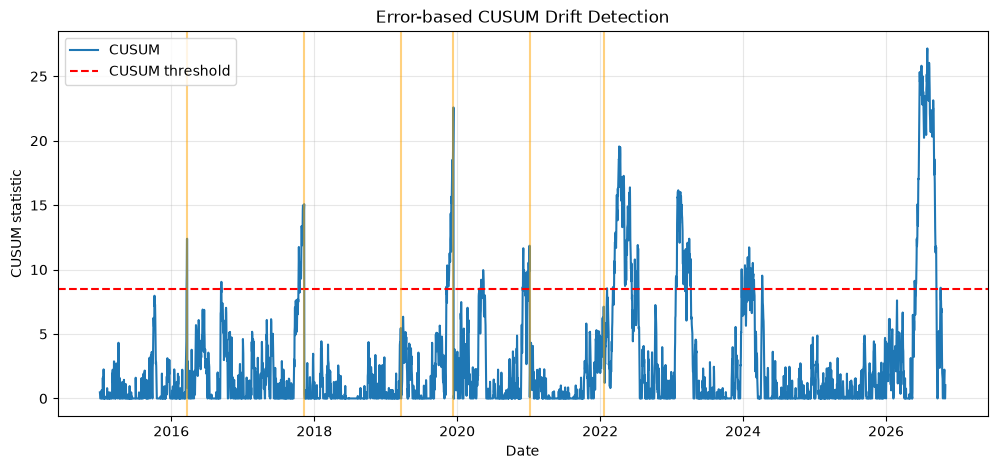

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

trace = pd.read_csv(
    "classification/stage2/alarms/knn_cusum_trace.csv",
    parse_dates=["date"]
)

alarms = trace[trace["alarm"]]

plt.figure(figsize=(12, 5))

plt.plot(trace["date"], trace["cusum"], label="CUSUM")

plt.axhline(
    8.5003,
    color="red",
    linestyle="--",
    label="CUSUM threshold"
)

for date in alarms["date"]:
    plt.axvline(date, color="orange", alpha=0.5)

plt.xlabel("Date")
plt.ylabel("CUSUM statistic")
plt.title("Error-based CUSUM Drift Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

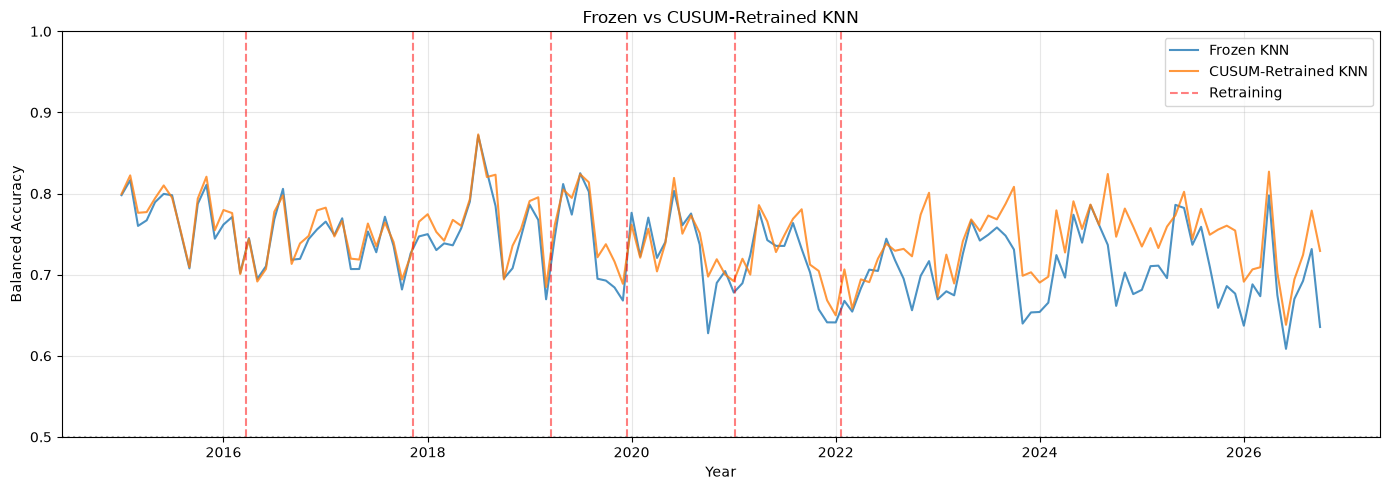

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score
import sys

sys.path.insert(0, "harness")
import dayahead as da

# Load predictions
frozen = pd.read_parquet(
    "classification/predictions/knn.parquet"
)

retrained = pd.read_parquet(
    "classification/predictions/knn_cusum.parquet"
)

# Calculate monthly balanced accuracy
def monthly_balanced_accuracy(df):
    df = df[df["split"] == "frozen"].copy()
    df["day"] = pd.to_datetime(da.market_day(df.index))

    monthly = df.groupby(
        df["day"].dt.to_period("M")
    ).apply(
        lambda g: balanced_accuracy_score(
            g["y_true"], g["y_pred"]
        )
    )

    monthly.index = monthly.index.to_timestamp()
    return monthly

frozen_ba = monthly_balanced_accuracy(frozen)
retrained_ba = monthly_balanced_accuracy(retrained)

# Load CUSUM retraining dates
trace = pd.read_csv(
    "classification/stage2/alarms/knn_cusum_trace.csv",
    parse_dates=["date"]
)

retrain_dates = (
    trace.loc[trace["alarm"], "date"]
    + pd.Timedelta(days=1)
)

# Plot
plt.figure(figsize=(14, 5))

plt.plot(
    frozen_ba.index,
    frozen_ba.values,
    label="Frozen KNN",
    alpha=0.8
)

plt.plot(
    retrained_ba.index,
    retrained_ba.values,
    label="CUSUM-Retrained KNN",
    alpha=0.8
)

for i, d in enumerate(retrain_dates):
    plt.axvline(
        d,
        color="red",
        linestyle="--",
        alpha=0.5,
        label="Retraining" if i == 0 else None
    )

plt.axhline(0.5, color="gray", linestyle=":", alpha=0.6)

plt.xlabel("Year")
plt.ylabel("Balanced Accuracy")
plt.title("Frozen vs CUSUM-Retrained KNN")
plt.ylim(0.5, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

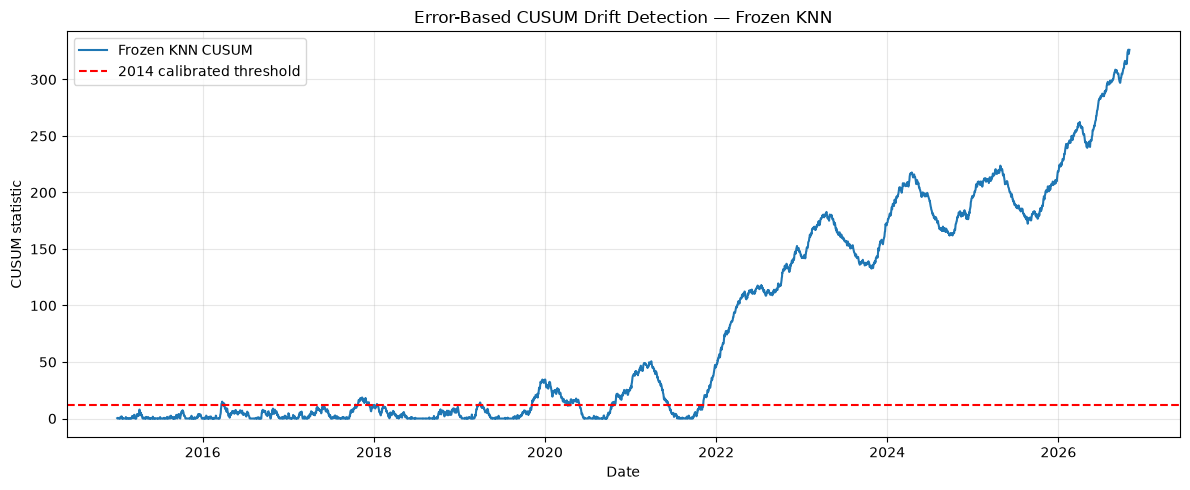

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

trace = pd.read_csv(
    "classification/stage2/alarms/knn_frozen_cusum_trace.csv",
    parse_dates=["date"]
)

plt.figure(figsize=(12, 5))

plt.plot(
    trace["date"],
    trace["cusum"],
    label="Frozen KNN CUSUM"
)

plt.axhline(
    trace["threshold"].iloc[0],
    color="red",
    linestyle="--",
    label="2014 calibrated threshold"
)

plt.xlabel("Date")
plt.ylabel("CUSUM statistic")
plt.title("Error-Based CUSUM Drift Detection — Frozen KNN")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

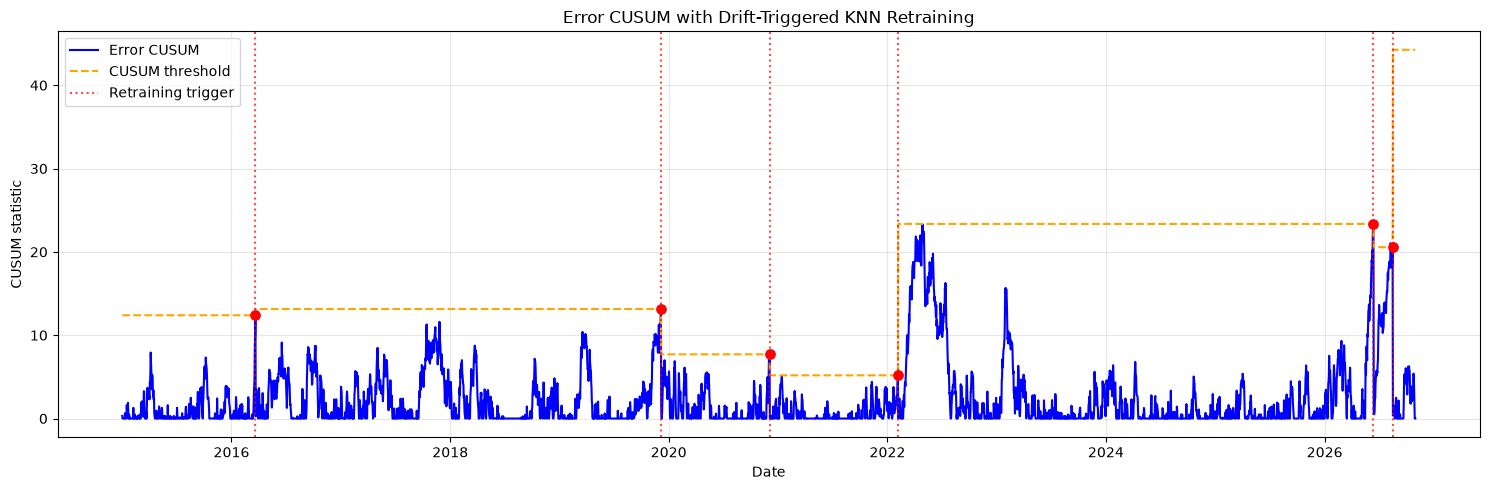

Number of retraining triggers: 6
      date     cusum  threshold
2016-03-21 12.392454  12.392454
2019-12-06 13.142795  13.142795
2020-12-03  7.704233   7.704233
2022-02-05  5.184220   5.184220
2026-06-13 23.355685  23.355685
2026-08-16 20.566257  20.566257


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CUSUM results
trace = pd.read_csv(
    "classification/stage2/alarms/knn_error_cusum_trace.csv",
    parse_dates=["date"]
)

# Extract alarm dates
alarms = trace[trace["alarm"] == True]

fig, ax = plt.subplots(figsize=(15, 5))

# CUSUM statistic
ax.plot(
    trace["date"],
    trace["cusum"],
    color="blue",
    label="Error CUSUM",
    linewidth=1.5
)

# CUSUM threshold (may change after retraining)
ax.plot(
    trace["date"],
    trace["threshold"],
    color="orange",
    linestyle="--",
    label="CUSUM threshold"
)

# Retraining dates
for i, date in enumerate(alarms["date"]):
    ax.axvline(
        date,
        color="red",
        linestyle=":",
        alpha=0.7,
        label="Retraining trigger" if i == 0 else None
    )

    ax.scatter(
        date,
        trace.loc[trace["date"] == date, "cusum"].iloc[0],
        color="red",
        s=45,
        zorder=5
    )

ax.set_title("Error CUSUM with Drift-Triggered KNN Retraining")
ax.set_xlabel("Date")
ax.set_ylabel("CUSUM statistic")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print alarm dates
print("Number of retraining triggers:", len(alarms))
print(alarms[["date", "cusum", "threshold"]].to_string(index=False))

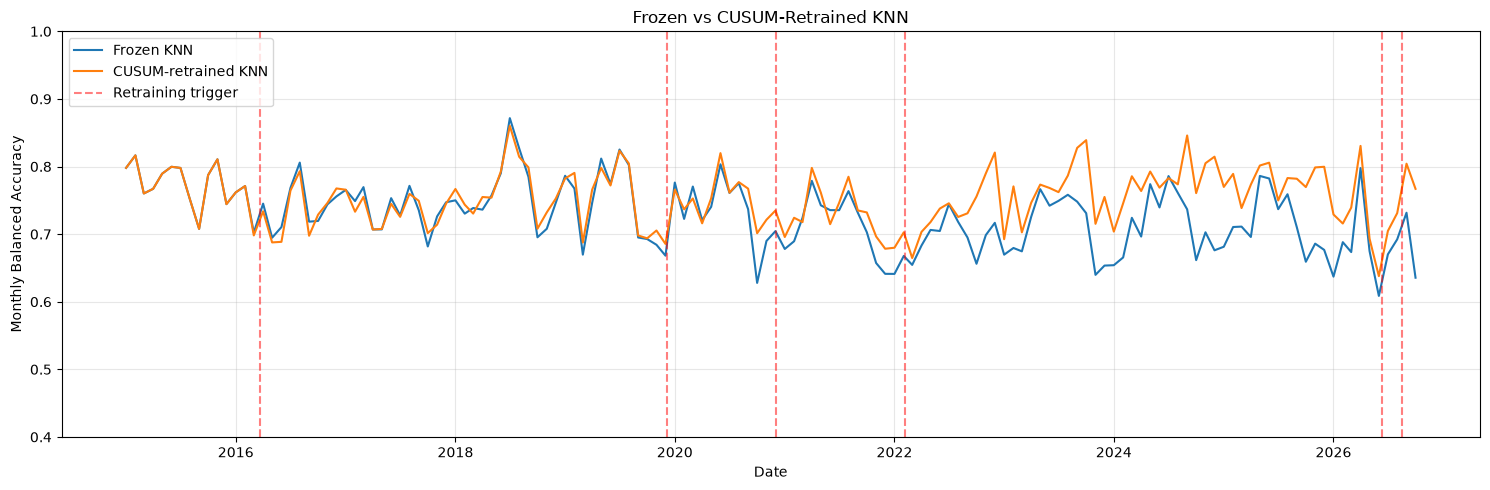

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import balanced_accuracy_score

# Change this if your notebook runs from the repository root
CLASS_DIR = Path("classification") if Path("classification").exists() else Path(".")

# Load predictions
frozen = pd.read_parquet(
    CLASS_DIR / "predictions" / "knn.parquet"
)

adaptive = pd.read_parquet(
    CLASS_DIR / "predictions" / "knn_error_cusum.parquet"
)

# Load retraining alarm dates
alarms = pd.read_csv(
    CLASS_DIR / "stage2" / "alarms" / "knn_error_cusum_alarms.csv",
    parse_dates=["date"]
)

# Monthly balanced accuracy
def monthly_ba(df):
    df = df.copy()

    # Convert timestamps to market days
    df["day"] = (
        pd.to_datetime(df.index) - pd.Timedelta(minutes=30)
    ).normalize()

    # Only evaluate 2015 onwards
    df = df[df["day"] >= "2015-01-01"]

    results = []

    for month, group in df.groupby(df["day"].dt.to_period("M")):
        ba = balanced_accuracy_score(
            group["y_true"],
            group["y_pred"]
        )

        results.append({
            "month": month.to_timestamp(),
            "balanced_accuracy": ba
        })

    return pd.DataFrame(results)

frozen_ba = monthly_ba(frozen)
adaptive_ba = monthly_ba(adaptive)

# Plot
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    frozen_ba["month"],
    frozen_ba["balanced_accuracy"],
    label="Frozen KNN",
    linewidth=1.5
)

ax.plot(
    adaptive_ba["month"],
    adaptive_ba["balanced_accuracy"],
    label="CUSUM-retrained KNN",
    linewidth=1.5
)

# Mark retraining dates
for i, date in enumerate(alarms["date"]):
    ax.axvline(
        date,
        color="red",
        linestyle="--",
        alpha=0.5,
        label="Retraining trigger" if i == 0 else None
    )

ax.set_title("Frozen vs CUSUM-Retrained KNN")
ax.set_xlabel("Date")
ax.set_ylabel("Monthly Balanced Accuracy")
ax.set_ylim(0.4, 1.0)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

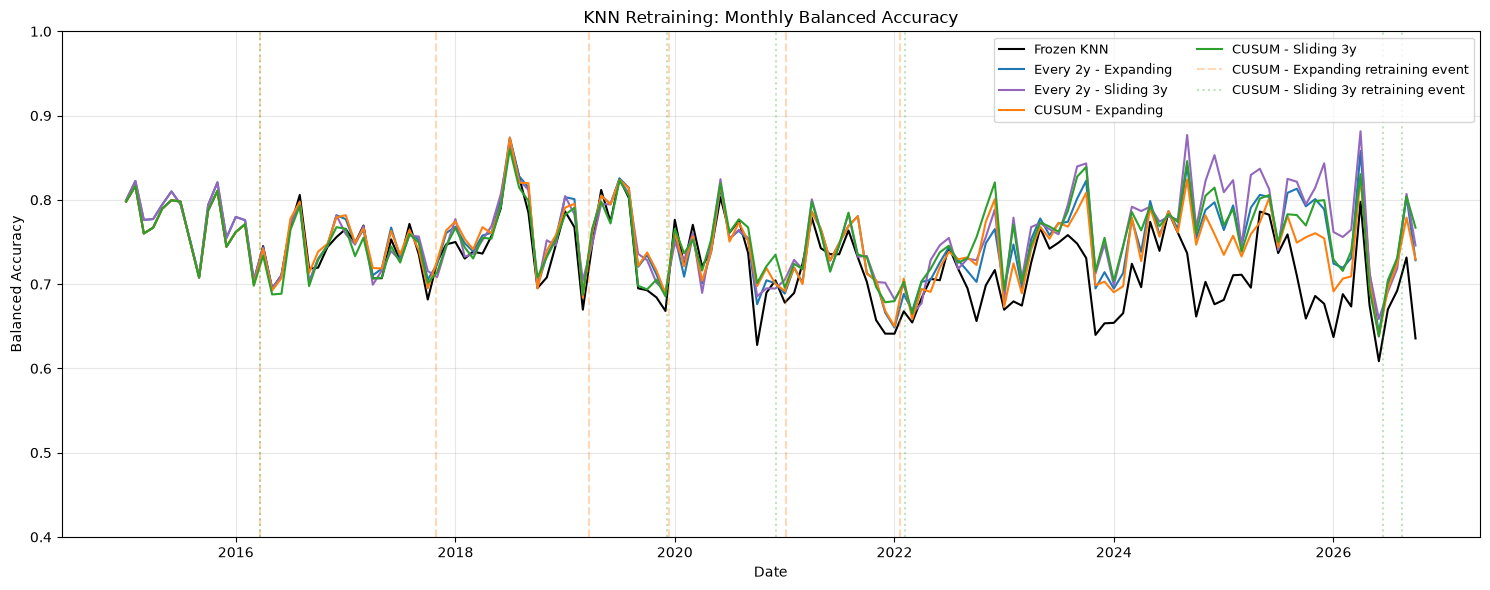

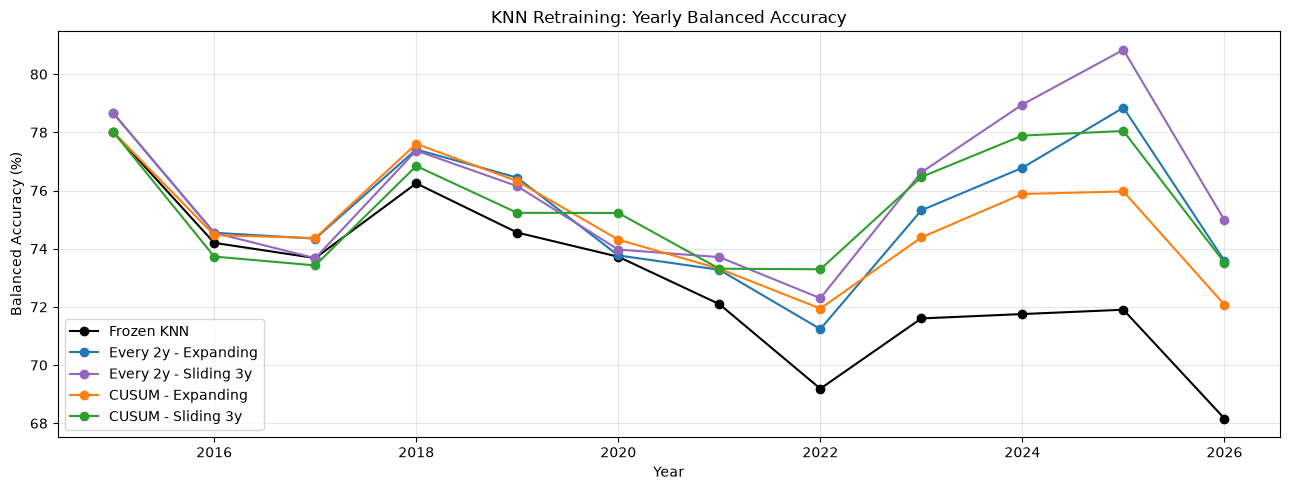

In [10]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import balanced_accuracy_score

CLASS_DIR = Path("classification") if Path("classification").exists() else Path(".")
PRED_DIR = CLASS_DIR / "predictions"
ALARM_DIR = CLASS_DIR / "stage2" / "alarms"

files = {
    "Frozen KNN": "knn.parquet",
    "Every 2y - Expanding": "knn_every2y_expanding.parquet",
    "Every 2y - Sliding 3y": "knn_every2y_sliding3y.parquet",
    "CUSUM - Expanding": "knn_error_cusum_expanding.parquet",
    "CUSUM - Sliding 3y": "knn_error_cusum_sliding3y.parquet",
}

colors = {
    "Frozen KNN": "black",
    "Every 2y - Expanding": "tab:blue",
    "Every 2y - Sliding 3y": "tab:purple",
    "CUSUM - Expanding": "tab:orange",
    "CUSUM - Sliding 3y": "tab:green",
}

# Load predictions
models = {}
for name, filename in files.items():
    path = PRED_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing prediction file: {path}")

    df = pd.read_parquet(path).copy()
    df["day"] = (
        pd.to_datetime(df.index) - pd.Timedelta(minutes=30)
    ).normalize()
    df = df[df["day"] >= "2015-01-01"]
    models[name] = df

# Ensure identical evaluation timestamps
shared_idx = models["Frozen KNN"].index
for df in models.values():
    shared_idx = shared_idx.intersection(df.index)

for name in models:
    models[name] = models[name].loc[shared_idx].sort_index()

# Check identical ground-truth labels
reference = models["Frozen KNN"]["y_true"]
for name, df in models.items():
    assert df["y_true"].equals(reference), (
        f"Label mismatch: {name}"
    )

def grouped_ba(df, frequency):
    rows = []
    periods = df["day"].dt.to_period(frequency)

    for period, group in df.groupby(periods):
        # BA requires both classes in the evaluation group
        if group["y_true"].nunique() < 2:
            continue

        ba = balanced_accuracy_score(
            group["y_true"], group["y_pred"]
        )
        rows.append({
            "date": period.to_timestamp(),
            "ba": ba
        })

    return pd.DataFrame(rows)

# Monthly and yearly results
monthly = {
    name: grouped_ba(df, "M")
    for name, df in models.items()
}
yearly = {
    name: grouped_ba(df, "Y")
    for name, df in models.items()
}

# Load actual retraining dates from metadata
import json

retrain_dates = {}
for name, filename in files.items():
    metadata_path = PRED_DIR / filename.replace(".parquet", ".json")

    if metadata_path.exists():
        with open(metadata_path) as f:
            info = json.load(f)
        retrain_dates[name] = pd.to_datetime(
            info.get("strategy", {}).get("retrains", [])
        )

# Monthly balanced accuracy
fig, ax = plt.subplots(figsize=(15, 6))

for name, result in monthly.items():
    ax.plot(
        result["date"], result["ba"],
        label=name, color=colors[name], linewidth=1.5
    )

# Show CUSUM retraining dates
for name, style in [
    ("CUSUM - Expanding", "--"),
    ("CUSUM - Sliding 3y", ":")
]:
    for i, date in enumerate(retrain_dates.get(name, [])):
        ax.axvline(
            date,
            color=colors[name],
            linestyle=style,
            alpha=0.3,
            label=f"{name} retraining event" if i == 0 else None
        )

ax.set(
    title="KNN Retraining: Monthly Balanced Accuracy",
    xlabel="Date",
    ylabel="Balanced Accuracy"
)
ax.set_ylim(0.4, 1.0)
ax.grid(alpha=0.3)
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

# Yearly balanced accuracy
fig, ax = plt.subplots(figsize=(13, 5))

for name, result in yearly.items():
    ax.plot(
        result["date"].dt.year,
        result["ba"] * 100,
        marker="o",
        label=name,
        color=colors[name]
    )

ax.set(
    title="KNN Retraining: Yearly Balanced Accuracy",
    xlabel="Year",
    ylabel="Balanced Accuracy (%)"
)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
